In [72]:
# Regression lineaire, Random forest, XGBoost, LightGBM, CatBoost, ExtraTrees​, PLS Regressor
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor,ExtraTreesRegressor
from sklearn.cross_decomposition import PLSRegression
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error
import hydroeval as hd
from sklearn.base import clone
from sklearn.pipeline import Pipeline

#plt.style.use("dark_background")

In [50]:
rl=LinearRegression()
rd=RandomForestRegressor()
xgb=XGBRegressor()
lgbm=LGBMRegressor()
cbc=CatBoostRegressor()
psl=PLSRegression()
extr=ExtraTreesRegressor()
liste_mode=[rl,rd,xgb,lgbm,cbc,psl,extr]

In [51]:
data=pd.read_excel("Data//DonneePreModel.xlsx")
data=data.dropna()
data.head()

,Date,Pluie,Debit,Debit-j+1,Debit-j+2,Debit-j+3,Debit-j+4,Debit-j+5,Cum_Pluie_15,Cum_Pluie_30,...,Debit-j-2,Debit-j-3,Debit-j-4,Debit-j-5,Cum_Pluie_110,Cum_Pluie_130,Cum_Pluie_150,Cum_Pluie_170,Cum_Pluie_180,Cum_Pluie_200
5,1992-01-06,0.0,16.610001,16.430000,16.200001,16.129999,15.90,15.66,0.0,0.0,...,17.000000,17.150000,17.280001,17.280001,0.0,0.0,0.0,0.0,0.0,0.0
6,1992-01-07,0.0,16.430000,16.200001,16.129999,15.900000,15.66,15.61,0.0,0.0,...,16.889999,17.000000,17.150000,17.280001,0.0,0.0,0.0,0.0,0.0,0.0
7,1992-01-08,0.0,16.200001,16.129999,15.900000,15.660000,15.61,15.48,0.0,0.0,...,16.610001,16.889999,17.000000,17.150000,0.0,0.0,0.0,0.0,0.0,0.0
8,1992-01-09,0.0,16.129999,15.900000,15.660000,15.610000,15.48,15.33,0.0,0.0,...,16.430000,16.610001,16.889999,17.000000,0.0,0.0,0.0,0.0,0.0,0.0
9,1992-01-10,0.0,15.900000,15.660000,15.610000,15.480000,15.33,15.21,0.0,0.0,...,16.200001,16.430000,16.610001,16.889999,0.0,0.0,0.0,0.0,0.0,0.0


In [52]:
cible=["Debit-j+1","Debit-j+2","Debit-j+3"]
data["Annee"]=data.Date.dt.year
data["Mois"]=data.Date.dt.month
data["Jour"]=data.Date.dt.day
data=data.drop(["Date","Debit-j+4","Debit-j+5"],axis=1)
train=data[data.Annee<=2014]
test=data[(2014<data.Annee) & (data.Annee<=2019)]
vald=data[(2019<data.Annee)]
X_vald=data[(2019<data.Annee)].drop(cible,axis=1)
y_vad=data[(2019<data.Annee)][cible]
X_train=train.drop(cible,axis=1)
X_test=test.drop(cible,axis=1)
y_train=train[cible]
y_test=test[cible]
X_train=X_train.drop("Annee",axis=1)
X_test=X_test.drop("Annee",axis=1)
X_va=X_vald.drop("Annee",axis=1)

Exog=train["Pluie"]
X=train["Debit"]

In [53]:
resultats={"Model":[],"Jour":[],"MAE":[],"RMSE":[],"kge":[],"r":[],"Alpha":[],"beta":[]}
def entrainement(model):
    print(model.__class__.__name__)
    for cib in cible:
        mod=clone(model)
        y_true=y_test[cib]
        y_true = np.asarray(y_true).ravel()
        mod.fit(X_train,y_train[cib])
        predi=mod.predict(X_test)
        predi = np.asarray(predi).ravel()
        mae=mean_absolute_error(predi,y_true)
        rmse=np.sqrt(mean_squared_error(predi,y_true))
        kge, r, alpha, beta = hd.evaluator(hd.kge,predi,y_true)
        resultats["Model"].append(model.__class__.__name__)
        resultats["Jour"].append(cib)
        resultats["MAE"].append(mae)
        resultats["RMSE"].append(rmse)
        resultats["kge"].append(kge)
        resultats["r"].append(r)
        resultats["Alpha"].append(alpha)
        resultats["beta"].append(beta)


for m in liste_mode:
    entrainement(m)


LinearRegression
RandomForestRegressor
XGBRegressor
LGBMRegressor
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.026306 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 4890
[LightGBM] [Info] Number of data points in the train set: 8390, number of used features: 21
[LightGBM] [Info] Start training from score 192.367112
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.002245 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 4890
[LightGBM] [Info] Number of data points in the train set: 8390, number of used features: 21
[LightGBM] [Info] Start training from score 192.366206
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.004396 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Tota

In [54]:
resultats=pd.DataFrame(resultats).sort_values(by="MAE")

In [55]:
resultats.set_index("Model")

,Jour,MAE,RMSE,kge,r,Alpha,beta
Model,,,,,,,
LinearRegression,Debit-j+1,5.224210,11.331633,[0.998826662636513],[0.9994066373626125],[1.000288369001596],[0.9990296986715326]
ExtraTreesRegressor,Debit-j+1,5.281334,11.698944,[0.9967021387751849],[0.9993702519323312],[0.9967628250396627],[1.0000020749871648]
RandomForestRegressor,Debit-j+1,5.527569,11.963099,[0.9961732363979598],[0.9993426871729354],[0.9963101378358238],[0.9992273573124292]
LGBMRegressor,Debit-j+1,6.576991,13.067259,[0.9952126197492019],[0.9992174846838939],[0.9955019802348084],[0.9985596883539536]
XGBRegressor,Debit-j+1,7.259190,14.186363,[0.9919048965995825],[0.9990921884407774],[0.9927705563707334],[0.996472717469829]
CatBoostRegressor,Debit-j+1,8.624051,16.565584,[0.9880370476846045],[0.998782845903995],[0.9891866755695788],[0.9950298109925819]
LinearRegression,Debit-j+2,11.232608,22.574744,[0.9964131721978287],[0.9976452517068071],[1.0000229247899721],[0.9972944559489562]
ExtraTreesRegressor,Debit-j+2,11.317411,23.078239,[0.990897079810278],[0.9975539224694449],[0.9912346933108714],[1.0002219444535914]
RandomForestRegressor,Debit-j+2,12.070287,24.658777,[0.9901037522960492],[0.9972065496910735],[0.9905103166348986],[0.999720243642381]


In [56]:
model1=LinearRegression()
model2=LinearRegression()
model3=LinearRegression()
scal=StandardScaler()
X_train_sc=scal.fit_transform(X_train)
X_test_sc=scal.transform(X_test)

model1.fit(X_train_sc,y_train["Debit-j+1"])
predic1=model1.predict(X_test_sc)

model2.fit(X_train_sc,y_train["Debit-j+2"])
predic2=model2.predict(X_test_sc)

model3.fit(X_train_sc,y_train["Debit-j+3"])
predic3=model3.predict(X_test_sc)

MAE1=mean_absolute_error(predic1,y_test["Debit-j+1"])
RMSE1=np.sqrt(mean_squared_error(predic1,y_test["Debit-j+1"]))

MAE2=mean_absolute_error(predic2,y_test["Debit-j+2"])
RMSE2=np.sqrt(mean_squared_error(predic2,y_test["Debit-j+2"]))

MAE3=mean_absolute_error(predic3,y_test["Debit-j+3"])
RMSE3=np.sqrt(mean_squared_error(predic3,y_test["Debit-j+3"]))

print(f"MAE j+1 : {mean_absolute_error(predic1,y_test["Debit-j+1"])} \n RMSE : {np.sqrt(mean_squared_error(predic1,y_test["Debit-j+1"]))}")
print(f"MAE j+2 : {mean_absolute_error(predic2,y_test["Debit-j+2"])} \n RMSE : {np.sqrt(mean_squared_error(predic2,y_test["Debit-j+2"]))}")
print(f"MAE j+3 : {mean_absolute_error(predic3,y_test["Debit-j+3"])} \n RMSE : {np.sqrt(mean_squared_error(predic3,y_test["Debit-j+3"]))}")

MAE j+1 : 5.224209628349959 
 RMSE : 11.331633025436794
MAE j+2 : 11.23260758636218 
 RMSE : 22.574744183224936
MAE j+3 : 17.471732804458608 
 RMSE : 32.67494047674568


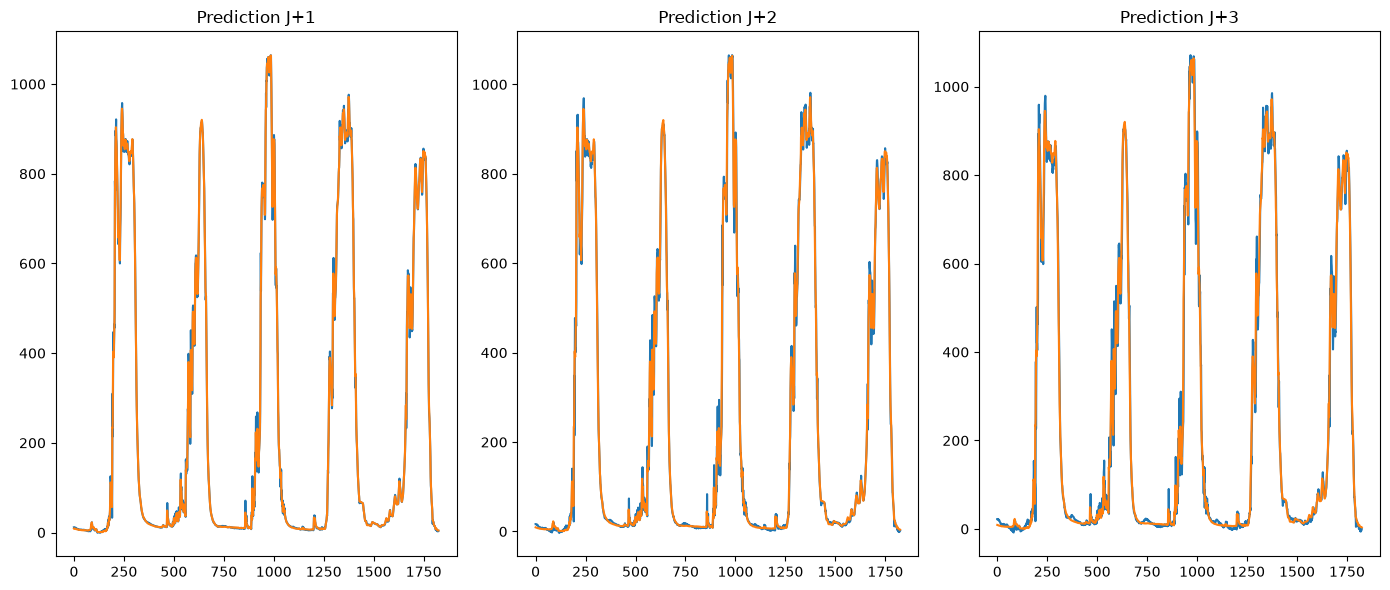

In [57]:
fig,axes=plt.subplots(1,3,figsize=(14,6))
axes=axes.flat
axes[0].plot(predic1,label="Vrai Valeur")
axes[0].plot(y_test["Debit-j+1"].values,label="Valeur Predict")
axes[0].set_title("Prediction J+1")

axes[1].plot(predic2,label="Vrai Valeur")
axes[1].plot(y_test["Debit-j+2"].values,label="Valeur Predict")
axes[1].set_title("Prediction J+2")

axes[2].plot(predic3,label="Vrai Valeur")
axes[2].plot(y_test["Debit-j+3"].values,label="Valeur Predict")
axes[2].set_title("Prediction J+3")
#plt.title("Comparaison des vrai valeur au valeur predit")
plt.tight_layout()

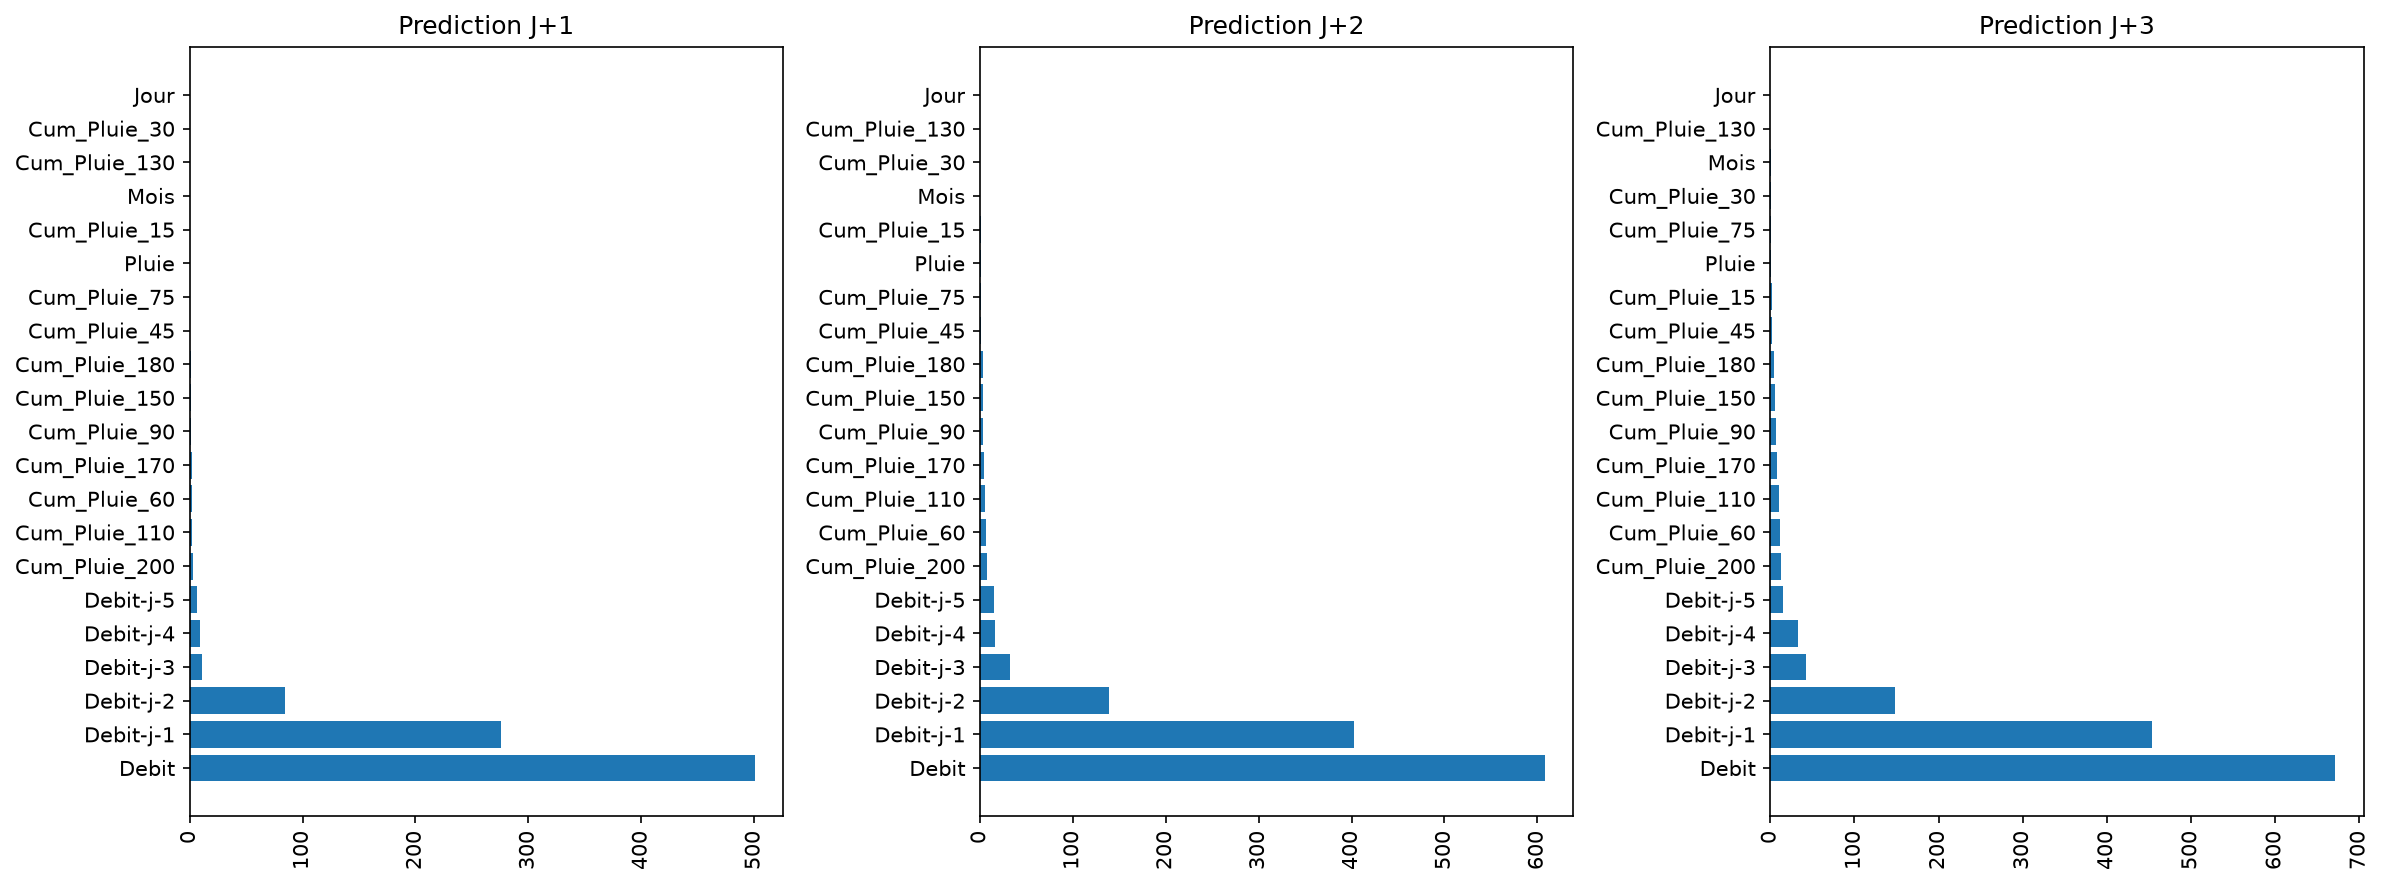

In [58]:
fig,axes=plt.subplots(1,3,figsize=(16,6),dpi=150)
don=pd.DataFrame({"Variable":X_train.columns,"Coefficient (avec abs)":np.abs(model1.coef_)}).sort_values(by="Coefficient (avec abs)",ascending=False)
axes[0].barh(don["Variable"],don["Coefficient (avec abs)"])
axes[0].set_title("Prediction J+1")

don=pd.DataFrame({"Variable":X_train.columns,"Coefficient (avec abs)":np.abs(model2.coef_)}).sort_values(by="Coefficient (avec abs)",ascending=False)
axes[1].barh(don["Variable"],don["Coefficient (avec abs)"])
axes[1].set_title("Prediction J+2")
plt.xticks(rotation=90)
don=pd.DataFrame({"Variable":X_train.columns,"Coefficient (avec abs)":np.abs(model3.coef_)}).sort_values(by="Coefficient (avec abs)",ascending=False)
axes[2].barh(don["Variable"],don["Coefficient (avec abs)"])
axes[2].set_title("Prediction J+3")
for ax in axes:
    ax.tick_params(axis='x', labelrotation=90)
    ax.set_xlim()
plt.tight_layout()
plt.show();

In [73]:

X=pd.concat([X_train,X_test],axis=0)
y=pd.concat([y_train,y_test],axis=0)
model = Pipeline([
    ("scaler", StandardScaler()),
    ("regression", LinearRegression())
])

model.fit(X,y)
predict=model.predict(X_va)



In [74]:
import joblib

joblib.dump(model,"modele_linear_regression.pkl")


['modele_linear_regression.pkl']

In [65]:
re=pd.DataFrame({"Date":["2023-12-26"],"Pluie_Bassin":[0],"Débit_Observé":[25.140571],"Prévision_J+1":[25.59363134],"Prévision_J+2":[26.94592527],"Prévision_J+3":[28.74232191]})
re.Date=pd.to_datetime(re.Date)

re

,Date,Pluie_Bassin,Débit_Observé,Prévision_J+1,Prévision_J+2,Prévision_J+3
0,2023-12-26,0,25.140571,25.593631,26.945925,28.742322


In [67]:
re.to_excel("prevision1.xlsx",index=False)

In [62]:
X_vald

,Pluie,Debit,Cum_Pluie_15,Cum_Pluie_30,Cum_Pluie_45,Cum_Pluie_60,Cum_Pluie_75,Cum_Pluie_90,Debit-j-1,Debit-j-2,...,Debit-j-5,Cum_Pluie_110,Cum_Pluie_130,Cum_Pluie_150,Cum_Pluie_170,Cum_Pluie_180,Cum_Pluie_200,Annee,Mois,Jour
10220,0.0,4.584000,5.150701,5.150701,24.870131,75.661444,155.028317,216.008025,4.577000,4.484000,...,4.978000,257.434315,276.376538,292.581342,367.561287,455.136272,718.048166,2020,1,1
10221,0.0,4.111000,5.001229,5.150701,16.209655,71.369466,155.028317,216.008025,4.584000,4.577000,...,4.677000,256.502459,276.376538,292.581342,343.998089,424.337648,718.048166,2020,1,2
10222,0.0,3.606000,4.671321,5.150701,16.209655,68.439644,154.645749,209.480722,4.111000,4.584000,...,4.444000,256.502459,276.376538,292.581342,342.432979,424.337648,716.319650,2020,1,3
10223,0.0,3.330000,0.614311,5.150701,16.209655,67.918178,154.645749,209.419121,3.606000,4.111000,...,4.484000,246.439694,276.376538,292.581342,333.211935,414.254307,695.932724,2020,1,4
10224,0.0,3.145000,0.185809,5.150701,16.209655,61.302289,138.759660,209.279293,3.330000,3.606000,...,4.577000,244.377778,276.376538,291.415397,332.584007,414.254307,655.707012,2020,1,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11670,0.0,27.854750,8.382097,29.387790,72.351305,115.269493,159.542649,242.035738,28.707000,29.512286,...,31.483428,277.005812,277.005812,293.031215,364.814209,370.799414,497.245288,2023,12,22
11671,0.0,27.233536,8.382097,28.048255,71.592994,115.269493,159.542649,242.035738,27.854750,28.707000,...,30.841499,277.005812,277.005812,293.031215,361.216568,370.799414,497.245288,2023,12,23
11672,0.0,26.551107,8.382097,28.048255,60.340297,113.536826,159.542649,241.870104,27.233536,27.854750,...,30.226429,277.005812,277.005812,292.966684,359.036417,368.677514,496.814061,2023,12,24
11673,0.0,25.837714,8.222802,25.424902,48.727751,96.061740,159.232133,241.870104,26.551107,27.233536,...,29.512286,268.869420,277.005812,292.966684,358.888163,368.677514,486.537134,2023,12,25
